In [3]:
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Adiciona o diretório 'src' ao caminho do Python
sys.path.append("../src")

from dataset import carregar_caminhos_dataset
from features import (
    extrair_hog, 
    criar_banco_gabor, extrair_gabor,
    extrair_bordas, extrair_atributos_geometricos
)
from preprocessing import converter_para_cinza, remover_ruido, aplicar_clahe
from segmentation import (
    aplicar_morfologia,
    binarizar_otsu,
    extrair_maior_componente_e_roi,
)

print("Módulos carregados com sucesso!")


Módulos carregados com sucesso!


# 1. Extração e Visualização dos Mapas de Gradiente HoG

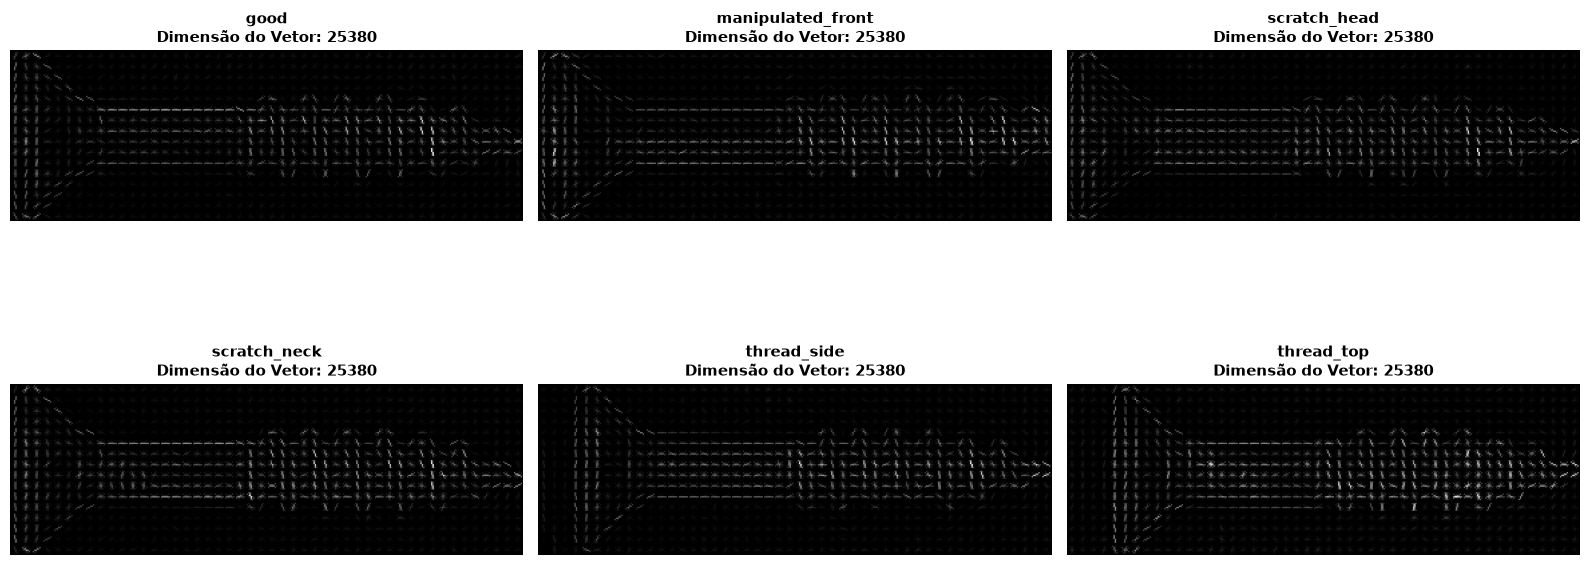

In [4]:
# 1. Carrega o mapeamento do dataset
df = carregar_caminhos_dataset(data_dir="../data")
categorias = [
    "good",
    "manipulated_front",
    "scratch_head",
    "scratch_neck",
    "thread_side",
    "thread_top",
]

# 2. Configura a figura para o grid 2x3
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, cat in enumerate(categorias):
    df_cat = df[(df["split"] == "test") & (df["classe"] == cat)]
    if df_cat.empty:
        continue

    caminho_img = df_cat.iloc[0]["caminho"]

    # --- Pipeline de Pré-processamento e ROI ---
    img_bgr = cv2.imread(caminho_img)
    cinza = converter_para_cinza(img_bgr)

    # Utiliza remover_ruido com metodo='gaussian' conforme seu preprocessing.py
    suavizada = remover_ruido(cinza, metodo="gaussian", ksize=(5, 5))

    _, mascara_otsu = binarizar_otsu(suavizada, inverter=True)
    mascara_limpa = aplicar_morfologia(
        mascara_otsu,
        tamanho_abertura=3,
        tamanho_fechamento=11,
        preencher_lacunas=True,
    )
    roi_cinza, mascara_roi, _ = extrair_maior_componente_e_roi(
        cinza, mascara_limpa, alinhar_eixo=True
    )

    # Aplica CLAHE diretamente na ROI recortada para realçar os sulcos 
    roi_clahe = aplicar_clahe(roi_cinza, clip_limit=2.0, tile_grid_size=(8, 8))


    # --- Extração do HoG (Milestone 3 - Task 1) ---
    vetor_hog, img_hog = extrair_hog(
        roi_clahe,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True,
    )

    # Visualização do mapa de gradientes do HoG
    axes[i].imshow(img_hog, cmap="gray")
    axes[i].set_title(
        f"{cat}\nDimensão do Vetor: {len(vetor_hog)}",
        fontsize=11,
        fontweight="bold",
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()


# 2. Filtros de Gabor

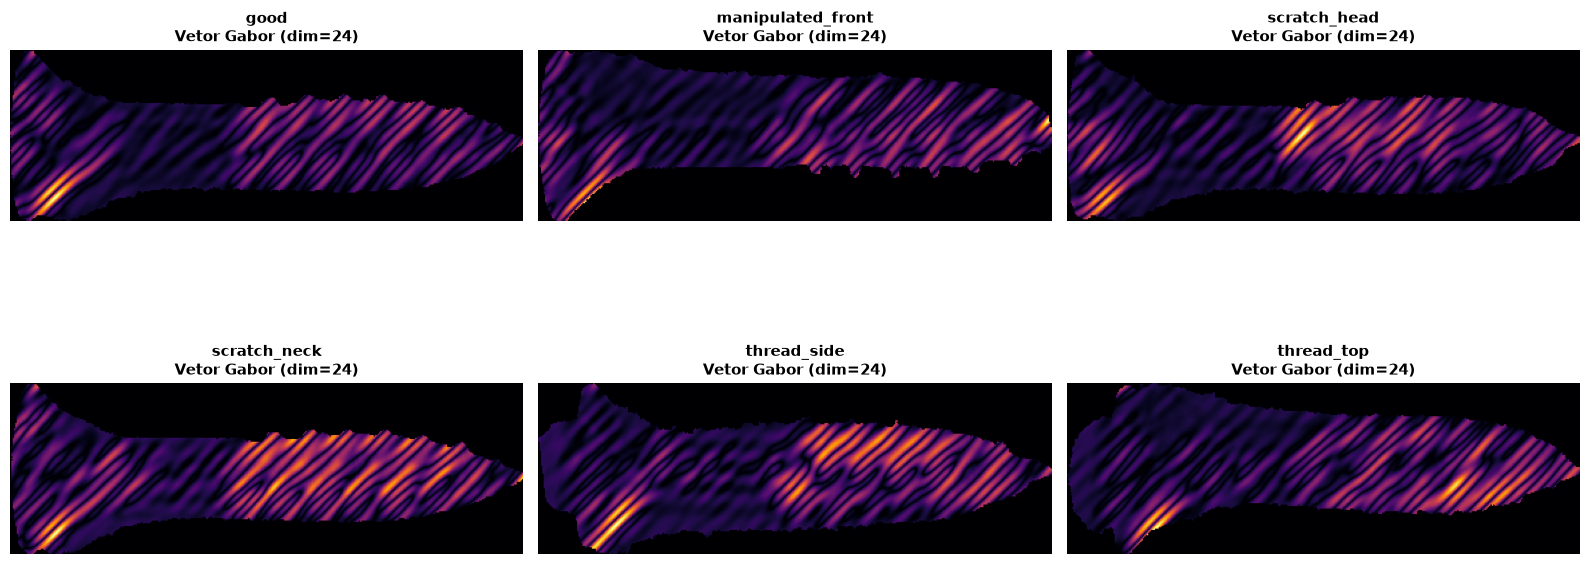

In [5]:
# Banco otimizado com lambdas [8.0, 12.0, 16.0]
banco_gabor = criar_banco_gabor(orientations=4, lambdas=[8.0, 12.0, 16.0])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

# Seleciona o filtro inclinado a ~45° e lambda intermediário (índice 4)
INDICE_FILTRO = 4

for i, cat in enumerate(categorias):
    df_cat = df[(df["split"] == "test") & (df["classe"] == cat)]
    if df_cat.empty:
        continue

    caminho_img = df_cat.iloc[0]["caminho"]

    # Pipeline de ROI
    img_bgr = cv2.imread(caminho_img)
    cinza = converter_para_cinza(img_bgr)
    suavizada = remover_ruido(cinza, metodo="gaussian", ksize=(5, 5))
    _, mascara_otsu = binarizar_otsu(suavizada, inverter=True)
    mascara_limpa = aplicar_morfologia(
        mascara_otsu,
        tamanho_abertura=3,
        tamanho_fechamento=11,
        preencher_lacunas=True,
    )
    roi_cinza, roi_mascara, _ = extrair_maior_componente_e_roi(
        cinza, mascara_limpa, alinhar_eixo=True
    )
    roi_clahe = aplicar_clahe(roi_cinza, clip_limit=2.0, tile_grid_size=(8, 8))

    # Extrai Gabor passando a mascara da ROI para zerar o fundo
    vetor_gabor, magnitudes_gabor = extrair_gabor(
        roi_clahe, roi_mascara=roi_mascara, kernels=banco_gabor, visualize=True
    )

    # Exibe o mapa de energia da textura (agora limpo e focado no parafuso)
    axes[i].imshow(magnitudes_gabor[INDICE_FILTRO], cmap="inferno")
    axes[i].set_title(
        f"{cat}\nVetor Gabor (dim={len(vetor_gabor)})",
        fontsize=11,
        fontweight="bold",
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# 3. Detecção de Bordas (canny / Sobbel)

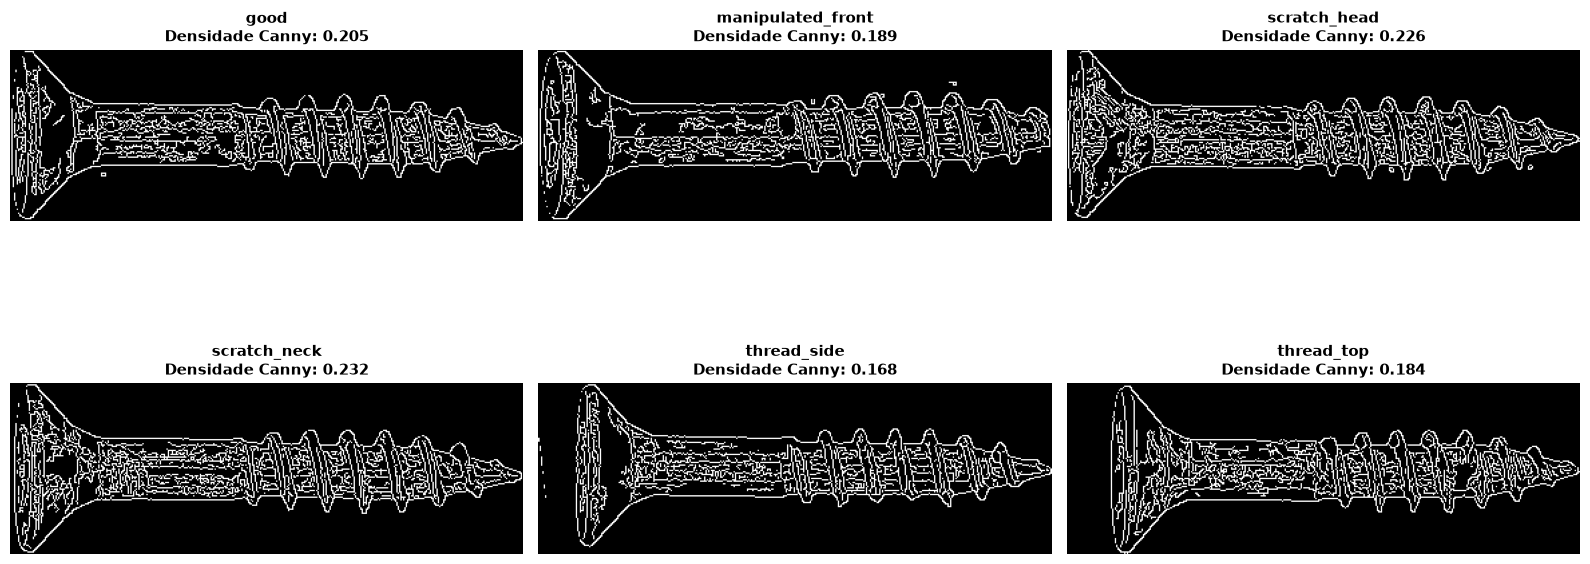

,categoria,densidade_canny,solidez,excentricidade,razao_aspecto
0,good,0.204605,0.776794,0.977030,3.0
1,manipulated_front,0.188717,0.785403,0.976362,3.0
2,scratch_head,0.225707,0.775503,0.976507,3.0
3,scratch_neck,0.232159,0.762987,0.977560,3.0
4,thread_side,0.167948,0.830038,0.970879,3.0
5,thread_top,0.183707,0.823069,0.971583,3.0


In [6]:
atributos_geom_lista = []
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, cat in enumerate(categorias):
    df_cat = df[(df["split"] == "test") & (df["classe"] == cat)]
    if df_cat.empty:
        continue

    caminho_img = df_cat.iloc[0]["caminho"]

    # Pipeline de ROI (Milestone 2)
    img_bgr = cv2.imread(caminho_img)
    cinza = converter_para_cinza(img_bgr)
    suavizada = remover_ruido(cinza, metodo="gaussian", ksize=(5, 5))
    _, mascara_otsu = binarizar_otsu(suavizada, inverter=True)
    mascara_limpa = aplicar_morfologia(
        mascara_otsu,
        tamanho_abertura=3,
        tamanho_fechamento=11,
        preencher_lacunas=True,
    )
    roi_cinza, roi_mascara, _ = extrair_maior_componente_e_roi(
        cinza, mascara_limpa, alinhar_eixo=True
    )
    roi_clahe = aplicar_clahe(roi_cinza, clip_limit=2.0, tile_grid_size=(8, 8))

    # 1. Extração de Bordas
    vetor_bordas, img_canny = extrair_bordas(
        roi_clahe, roi_mascara=roi_mascara, visualize=True
    )

    # 2. Extração Geométrica
    vetor_geom = extrair_atributos_geometricos(roi_mascara)
    atributos_geom_lista.append(
        {
            "categoria": cat,
            "densidade_canny": vetor_bordas[0],
            "solidez": vetor_geom[2],
            "excentricidade": vetor_geom[3],
            "razao_aspecto": vetor_geom[5],
        }
    )

    # Exibe a imagem de bordas Canny
    axes[i].imshow(img_canny, cmap="gray")
    axes[i].set_title(
        f"{cat}\nDensidade Canny: {vetor_bordas[0]:.3f}",
        fontsize=11,
        fontweight="bold",
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Exibe tabela com comparação dos atributos geométricos e de bordas
df_geom = pd.DataFrame(atributos_geom_lista)
display(df_geom)
